---
# 1. Loading & inspecting the data

Dataset fot this project is obtained from survey of students in secondary school regarding their grades in subject Math. The dataset provides information about students' results from three key assessments: first period grade, second period grade and their final grade (possible scores are from 0 to 20) as well as socio-demographic and educational features.

## Loading the libraries and dataset

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [40]:
math_df = pd.read_csv("student-mat.csv")
math_df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## Data summary

In [41]:
math_df.shape

(395, 33)

In [42]:
math_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [43]:
math_df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [44]:
math_df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


The average grades are not that high - means for G1, G2 and G3 are around 10-11 with standard deviation of 3-5 that indicates a roughly "middle" performance. It is interesting that standard deviation increases from G1 to G3 - final grades vary more than end of period grades. 

In [45]:
numeric_columns = math_df.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns =  math_df.select_dtypes(exclude=[np.number]).columns.tolist()

print('Numeric variables:')
print(numeric_columns)
print()
print('Categorical variables:')
print(categorical_columns)

Numeric variables:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical variables:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


Everything is imported correctly - in this dataset we have a mixture of numeric and categorical variables. Target variable for this project is G3 - numeric variable that represents a final grade in math in range from 0 to 20. The goal of this project is to predict this final math grade (G3) using data on a student's background and earlier performance.

---
# 2. EDA & cleaning

In [46]:
# defining expected ranges
numeric_expected_ranges = {
    "age": (15, 22),
    "Medu": (0, 4),
    "Fedu": (0, 4),
    "traveltime": (1, 4),
    "studytime": (1, 4),
    "failures": (0, 4),
    "famrel": (1, 5),
    "freetime": (1, 5),
    "goout": (1, 5),
    "Dalc": (1, 5),
    "Walc": (1, 5),
    "health": (1, 5),
    "absences": (0, 93),
    "G1": (0, 20),
    "G2": (0, 20),
    "G3": (0, 20),}

# filtering rows where values are outside of the expected range
for col, (low, high) in numeric_expected_ranges.items():
    if col in math_df.columns:
        out_of_range = math_df[(math_df[col] < low) | (math_df[col] > high)]
        print(f"\nColumn: {col}, expected range [{low}, {high}]")
        print("Number of out-of-range rows:", len(out_of_range))
        if len(out_of_range) > 0:
            display(out_of_range[[col]])



Column: age, expected range [15, 22]
Number of out-of-range rows: 0

Column: Medu, expected range [0, 4]
Number of out-of-range rows: 0

Column: Fedu, expected range [0, 4]
Number of out-of-range rows: 0

Column: traveltime, expected range [1, 4]
Number of out-of-range rows: 0

Column: studytime, expected range [1, 4]
Number of out-of-range rows: 0

Column: failures, expected range [0, 4]
Number of out-of-range rows: 0

Column: famrel, expected range [1, 5]
Number of out-of-range rows: 0

Column: freetime, expected range [1, 5]
Number of out-of-range rows: 0

Column: goout, expected range [1, 5]
Number of out-of-range rows: 0

Column: Dalc, expected range [1, 5]
Number of out-of-range rows: 0

Column: Walc, expected range [1, 5]
Number of out-of-range rows: 0

Column: health, expected range [1, 5]
Number of out-of-range rows: 0

Column: absences, expected range [0, 93]
Number of out-of-range rows: 0

Column: G1, expected range [0, 20]
Number of out-of-range rows: 0

Column: G2, expect

In [47]:
# defining expected categories
categorical_expected_values = {
    "school": {"GP", "MS"},
    "sex": {"F", "M"},
    "address": {"U", "R"},
    "famsize": {"LE3", "GT3"},
    "Pstatus": {"T", "A"},
    "Mjob": {"teacher", "health", "services", "at_home", "other"},
    "Fjob": {"teacher", "health", "services", "at_home", "other"},
    "reason": {"home", "reputation", "course", "other"},
    "guardian": {"mother", "father", "other"},
    "schoolsup": {"yes", "no"},
    "famsup": {"yes", "no"},
    "paid": {"yes", "no"},
    "activities": {"yes", "no"},
    "nursery": {"yes", "no"},
    "higher": {"yes", "no"},
    "internet": {"yes", "no"},
    "romantic": {"yes", "no"},}

# comparing sets of observed categories with sets of expected categories
for col, allowed in categorical_expected_values.items():
    if col in math_df.columns:
        unique_vals = set(math_df[col].unique())
        unexpected_vals = unique_vals - allowed
        print(f"\nColumn: {col}")
        print("Unique values in data:", unique_vals)
        print("Unexpected values:", unexpected_vals)


Column: school
Unique values in data: {'MS', 'GP'}
Unexpected values: set()

Column: sex
Unique values in data: {'M', 'F'}
Unexpected values: set()

Column: address
Unique values in data: {'U', 'R'}
Unexpected values: set()

Column: famsize
Unique values in data: {'LE3', 'GT3'}
Unexpected values: set()

Column: Pstatus
Unique values in data: {'A', 'T'}
Unexpected values: set()

Column: Mjob
Unique values in data: {'other', 'services', 'teacher', 'at_home', 'health'}
Unexpected values: set()

Column: Fjob
Unique values in data: {'other', 'at_home', 'teacher', 'services', 'health'}
Unexpected values: set()

Column: reason
Unique values in data: {'course', 'reputation', 'other', 'home'}
Unexpected values: set()

Column: guardian
Unique values in data: {'mother', 'father', 'other'}
Unexpected values: set()

Column: schoolsup
Unique values in data: {'no', 'yes'}
Unexpected values: set()

Column: famsup
Unique values in data: {'no', 'yes'}
Unexpected values: set()

Column: paid
Unique value

Before inspecting what variables are actually statistically significant for modelling, I wanted to visually inspect few variables first. I chose to inspect the target (G3), and variables G1, G2, absences and studytime because, to me, they seem that they could be important in predicting final grade (later we will inspect how important they really are).

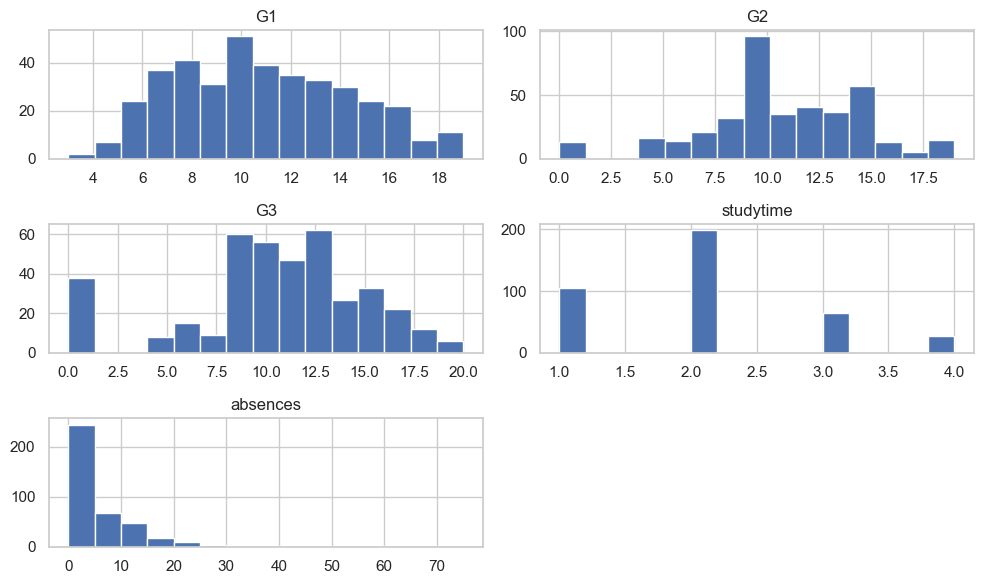

In [48]:
sns.set(style="whitegrid")

variables_to_plot = ["G1", "G2", "G3", "studytime", "absences"]

math_df[variables_to_plot].hist(bins=15, figsize=(10, 6))
plt.tight_layout()
plt.show()

From these histograms, we can see that the distribution of G1 is close to normal distribution, the distribution of G2 is concentrated near 10, and the distribution of G3 is more spread out and has many 0 values. This is expected (std from G3 was the biggest).\
As for the studytime, we can see that for most students studytime is 2.0, meaning they study between 2 and 5 hours per week.\
The distribution of absences is heavy-tailed - there are a lot of students with small number of absences, and not so many students with 15+ absences. We can see that the range for absences goes above 70, so, although not visible here, there could be a few students with very high absences that are far from majority, so this variable should be inspected for outliers.

## Examining the presence of zero final grades

In [49]:
g3_zero = math_df[math_df["G3"] == 0]
print("Number of rows where G3=0:", len(g3_zero))

g3_zero[["G1", "G2", "G3"]].describe()

g3_zero_display = g3_zero[["age", "failures", "absences", "G1", "G2", "G3"]]
g3_zero_display

Number of rows where G3=0: 38


,age,failures,absences,G1,G2,G3
128,18,2,0,7,4,0
130,15,2,0,12,0,0
131,15,0,0,8,0,0
134,15,0,0,9,0,0
135,15,0,0,11,0,0
136,17,0,0,10,0,0
137,16,2,0,4,0,0
140,15,0,0,7,9,0
144,17,3,0,5,0,0
146,15,3,0,6,7,0


When looking at students with G3 score = 0, we notice that there are in total 38 of them, but some of them have non-zero G1 and/or G2. \
For example, we can see that we even have students who scored 10 in G1 and 10 in G2, but still have 0 for G3 score.\
Also, some of them have failed classes before, and some of them didn't, but all of them have 0 absences.\
Besides this, I do not see here a clear pattern and the official documentation of the dataset does not provide any explanation for such cases.

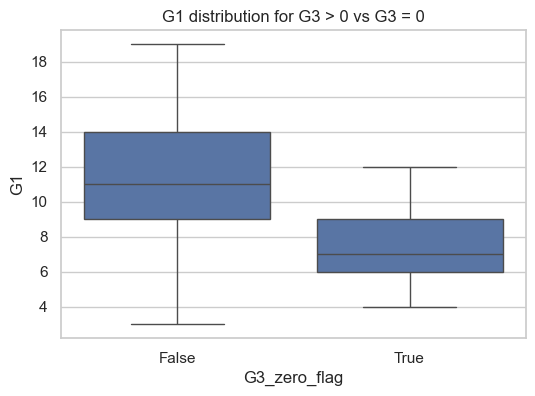

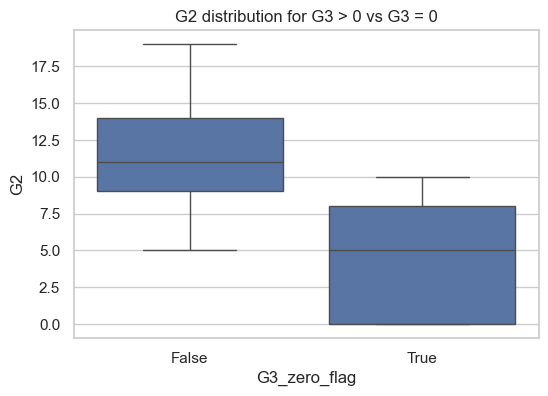

In [50]:
math_df["G3_zero_flag"] = (math_df["G3"] == 0)

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=math_df,
    x="G3_zero_flag",
    y="G1")
plt.title("G1 distribution for G3 > 0 vs G3 = 0")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=math_df,
    x="G3_zero_flag",
    y="G2")
plt.title("G2 distribution for G3 > 0 vs G3 = 0")
plt.show()

When inspecting whether G1 and G2 score for G3 = 0 students are comparable, or very different from the rest, we see that G3 = 0 group has lower period grades on average. From the first boxplot, it looks like students who end up with G3 = 0 tend to have weaker G1 on average, but still many of them are far from 0 (G1 is around 6-8), so we cannot explain a final grade in a simple, linear way. Second boxplot is similar to the first, where students with G3 = 0 have lower G2 on average than students with G3 > 0. But, again, the range is here quite wide - some students have G2 = 0, while others have it up to around 10. 

Although this would be interesting to investigate furhter to see if these are represting some kind of special-cases (for example maybe someone showed up on the final exam and didn't write a single word on paper, maybe someone didn't show up at all, maybe someone droped out, maybe 0 marks a missing grade etc.), I have chosen to remove them from my regression task because such cases can strongly influence regression, espsecially evaluation metric lik squared-error. \
So, to avoid mixing such unclear and potentially special cases into my regression target, I decided to exclude rows with G3 = 0 for the main modeling dataset, and focus on predicting G3 for students with valid final grades, i.e. G3 > 0.

Original shape: (395, 34)
Cleaned shape (G3 > 0): (357, 34)

G3 describe after removing zeros:
count    357.000000
mean      11.523810
std        3.227797
min        4.000000
25%        9.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


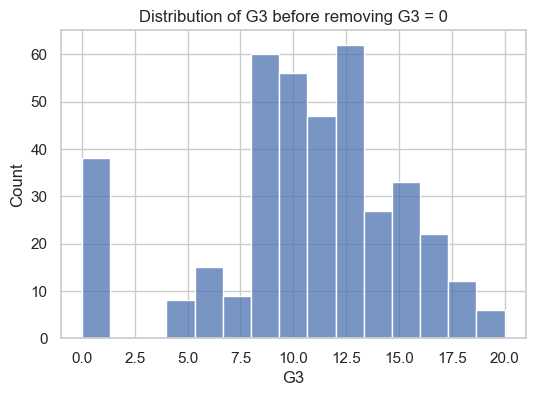

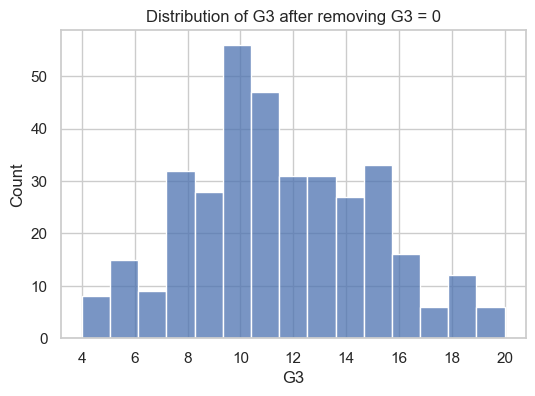

In [51]:
# creating new cleaned dataset (regression dataset)
math_df_clean = math_df[math_df["G3"] > 0].copy()

print("Original shape:", math_df.shape)
print("Cleaned shape (G3 > 0):", math_df_clean.shape)
print()

# checking G3 distribution in regression dataset
print("G3 describe after removing zeros:")
print(math_df_clean["G3"].describe())

# histogram of G3 before cleaning
plt.figure(figsize=(6, 4))
sns.histplot(math_df["G3"], bins=15, kde=False)
plt.title("Distribution of G3 before removing G3 = 0")
plt.xlabel("G3")
plt.ylabel("Count")
plt.show()

# histogram of G3 after cleaning
plt.figure(figsize=(6, 4))
sns.histplot(math_df_clean["G3"], bins=15, kde=False)
plt.title("Distribution of G3 after removing G3 = 0")
plt.xlabel("G3")
plt.ylabel("Count")
plt.show()

As we can see from the output, we have removed all the student with G3 = 0, which has changed the distribution of our target variable G3. Mean has increased from about 10.4 to about 11.5 and the minimum is now 4 instead of 0. Also, we can see that the distribution is a bit smoother in its shape and that there is no spike at 0.

## Searching for outliers

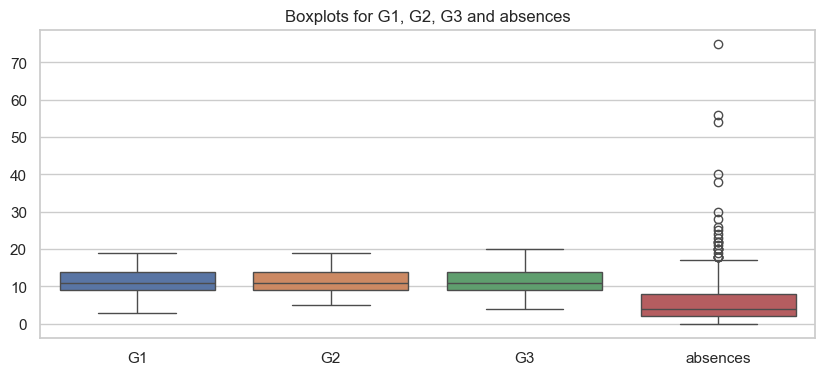

In [52]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=math_df_clean[["G1", "G2", "G3", "absences"]])
plt.title("Boxplots for G1, G2, G3 and absences")
plt.show()

Here we can see that there are a lot of outliers in absences boxplot. This boxplot actually allowes us to see that the distribution of absences has an even longer tail than what we have assumed based on the histogram. Here we can see that there is a student that has over 70 absences (which is not visible in histogram), so the range for absences is quite big (from 0 to 70+). But, it seems that most of the students have low absences (mean around 5), and few students have high to very high absences (30+); they are far from the majority so they are the candidates for outliers.

In [53]:
# IQR-based outlier detection for absences
q1 = math_df_clean["absences"].quantile(0.25)
q3 = math_df_clean["absences"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print()

# identifying outliers
absences_outliers = math_df_clean[
    (math_df_clean["absences"] < lower_bound) | (math_df_clean["absences"] > upper_bound)]

print("Number of absences outliers:", len(absences_outliers))
print()
print('Statistics for "outlier students":')
absences_outliers["absences"].describe()

Q1: 2.0 Q3: 8.0 IQR: 6.0
Lower bound: -7.0
Upper bound: 17.0

Number of absences outliers: 25

Statistics for "outlier students":


count    25.000000
mean     27.800000
std      14.381701
min      18.000000
25%      20.000000
50%      22.000000
75%      28.000000
max      75.000000
Name: absences, dtype: float64

Using IQR method to detect outliers in absences variable, we have calculated that there are 25 outliers - 25 students have more than 17 absences. There are no students that have less than -7 absences, which makes sense because you cannot have a negative number of absences (the lowest value for absences is 0).\
On average, "outlier students" missed about 27 classes. The "least extreme" "outlier student" has 18 absences, while the student with most absences has missed 75 classes. \
According to IQR method, outliers in absences are students missing from 18 up to 75 classes, with a typical "outlier student" missing around 20-28 classes, which is far from the majority of students who have 2 to 8 absences.

When looking at majority of students with 2-8 absences, a student with 75 absences can be considered as an extreme outlier. To help us decide what to do with these outliers (remove them, log transform them, cap them...), let's look at the relationship between absences and G3. We can use a scatterplot to see how "extreme" absences (based on IQR) relate to our target variable G3. In other words, do students with "extreme" absences also have very low final grades?

absences_outlier
False    332
True      25
Name: count, dtype: int64


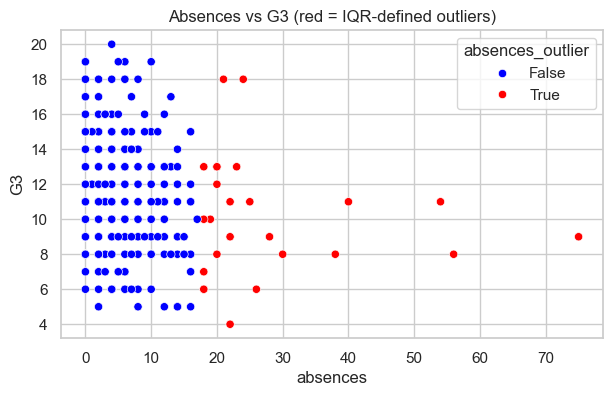

In [54]:
# creating a flag for absences outliers
math_df_clean["absences_outlier"] = math_df_clean["absences"] > upper_bound

print(math_df_clean["absences_outlier"].value_counts())

# scatterplot: absences vs G3, color by outlier flag
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=math_df_clean,
    x="absences",
    y="G3",
    hue="absences_outlier",
    palette={False: "blue", True: "red"},)
plt.title("Absences vs G3 (red = IQR-defined outliers)")
plt.show()

Most students that have absences between 0 and 17 (blue points) have G3 spread roughly from 6 to 16. \
Outliers marked using IQR (red points) mostly have moderate grades. We can see that most of the red points have G3 between 7.5 and 13, with some exceptions. This indicates that there is some kind of relationship between absences and G3, but it is noisy, so we cannot say that many absences will necessarily result in a bad grade. \
For example, we have a few red points with around 21-25 absences and G3 of 18. These could be generaly good students who may have been seriously ill or had other issues in that school year.\
Also, we have a few red poitns with roughly the same number of absences (around 18-25), but with very low G3 (between 4 and 6).

To investigate further into the joint pattern of absences and G3, we can try DBSCAN for outlier detection and check how it compares with IQR.

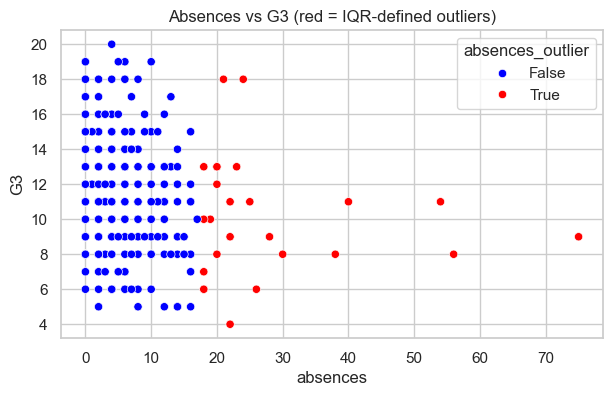

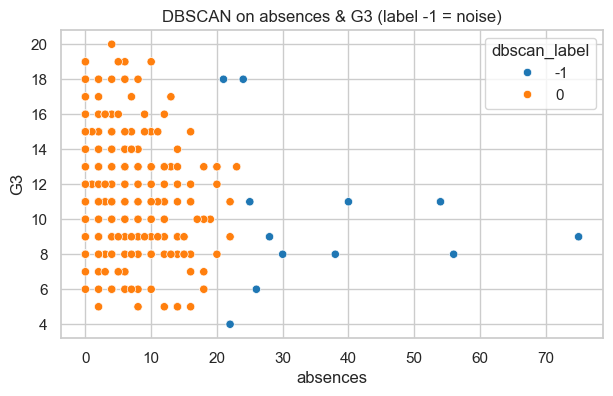

DBSCAN labels value counts:
dbscan_label
 0    345
-1     12
Name: count, dtype: int64
Detected 12 outliers.


In [55]:
X = math_df_clean[["absences", "G3"]].values

# scaling features so both dimensions are comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

dbscan = DBSCAN(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

# -1 means "noise" (outlier), 0,1,2,... are cluster labels
math_df_clean["dbscan_label"] = labels


# previous scatterplot (IQR based)
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=math_df_clean,
    x="absences",
    y="G3",
    hue="absences_outlier",
    palette={False: "blue", True: "red"},)
plt.title("Absences vs G3 (red = IQR-defined outliers)")
plt.show()

# clusters vs noise
plt.figure(figsize=(7, 4))
sns.scatterplot(
    x="absences",
    y="G3",
    hue="dbscan_label",
    palette="tab10",
    data=math_df_clean)
plt.title("DBSCAN on absences & G3 (label -1 = noise)")
plt.show()

print("DBSCAN labels value counts:")
print(math_df_clean["dbscan_label"].value_counts())
outliers = labels == -1
print(f"Detected {np.sum(outliers)} outliers.")

DBSCAN plot shows that the main cluster has 345 points, while the noise or outliers has 12 points. "Outlier students" according to DBSCAN plot are relatively isolated in the absences-G3 plane, but we can separate them in two groups: moderate absences (21-30) and some with very high absences (38-75). Again, we can try to generalize and say that most outliers have G3 score between 8 and 11 points, but still we have outliers who have around 20-25 abscences and either very low (4-6) or very high (18) G3 score.

Using DBSCAN, we can see a clear difference in detection outliers - where IQR detected 25 "outlier students", DBSCAN (with epsilon = 0.5 and min_samples = 5) detected 12. This is no surprise because IQR marked any student with 17+ absences as an outlier, while DBSCAN considered density, and therefore didn't mark some students with absences just above 17 as outliers - because they are lying among other points with similar G3. In addition, IGR takes only absences into consideration (one-dimensional), while DBSCAN investigates joint pattern of absences and G3 and then looks at isolated cases according to given hyperparameters. Although I can play here with different hyperparameters for DBSCAN, let's finally see which variables will be actually significant for our model.

---
# 3. Feature selection

## Feature selection method 1 - correlations

numeric --> numeric

In [56]:
numeric_cols_clean = math_df_clean.select_dtypes(include=[np.number]).columns.tolist()

corr_matrix = math_df_clean[numeric_cols_clean].corr()

corr_with_g3 = corr_matrix["G3"].sort_values(ascending=False)
print("Correlations with G3 (numeric features):")
print(corr_with_g3)

Correlations with G3 (numeric features):
G3              1.000000
G2              0.965583
G1              0.891805
Medu            0.190308
Fedu            0.158811
studytime       0.126728
dbscan_label    0.083347
famrel          0.037711
freetime       -0.021589
health         -0.081691
traveltime     -0.099785
age            -0.140372
Dalc           -0.140690
goout          -0.177383
Walc           -0.190054
absences       -0.213129
failures       -0.293831
Name: G3, dtype: float64


As expected, variables G2 and G3 have the strongest correlation with target (G3). Their relationship is a strong positive linear relationship. Other variables do not have such strong relationships (much weaker correlations), but we can visually investigate a few with the highest absolute Pearson correlation value, like: failures (number of past class failures), absences, Medu (mother's education) and Walc (weekend alchocol consumption).

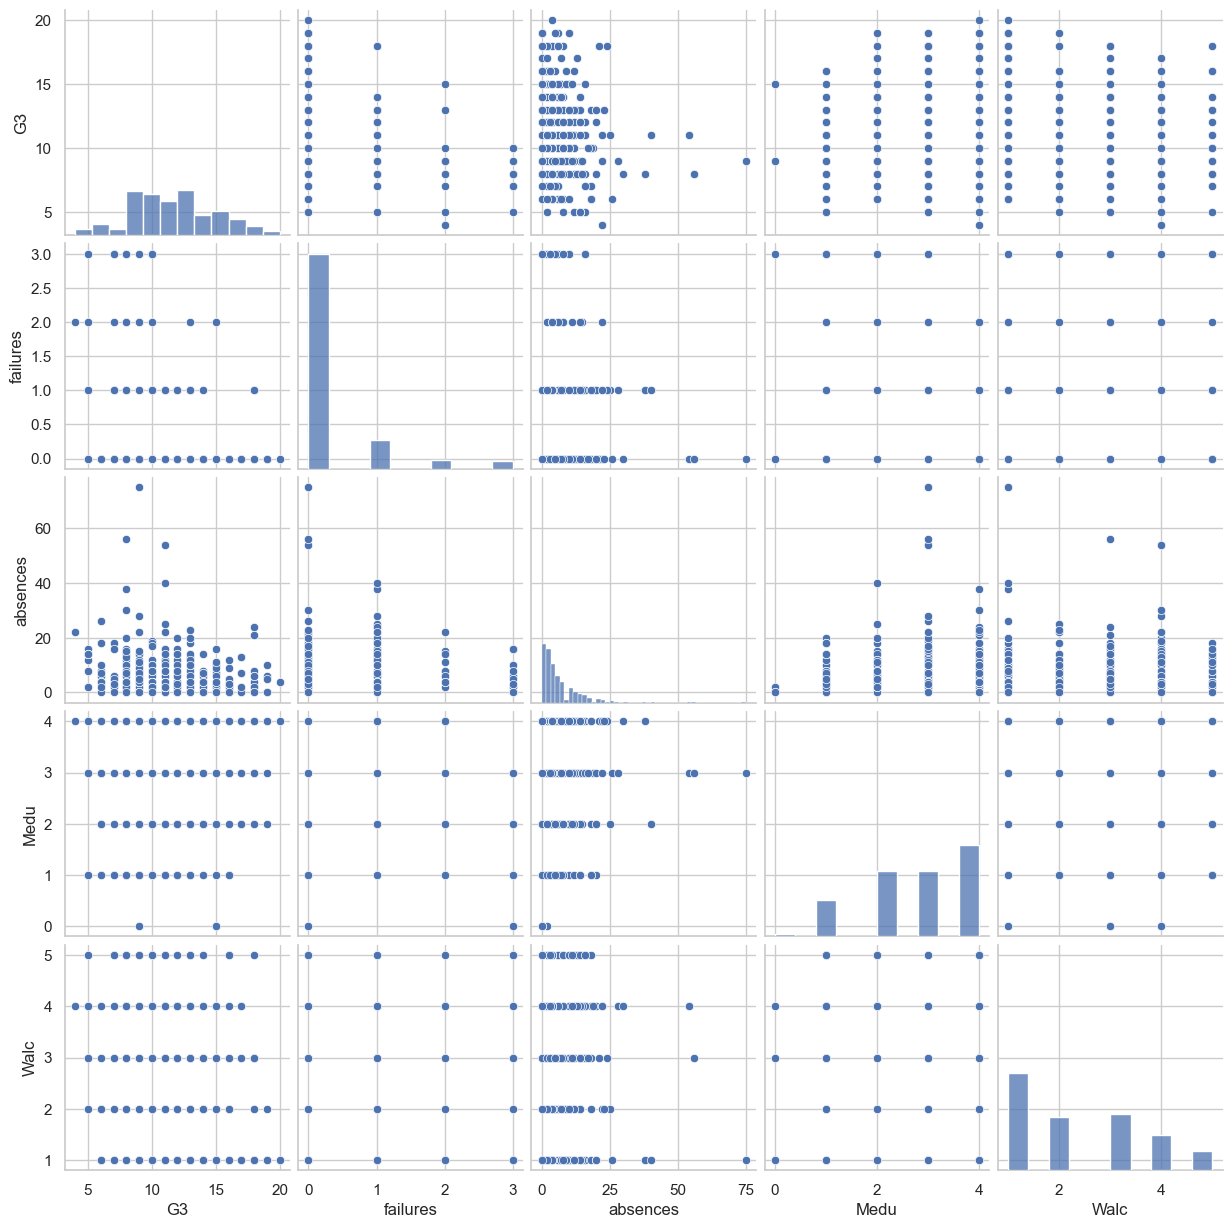

In [57]:
cols_for_pairplot = ["G3", "failures", "absences", "Medu", "Walc"]

sns.pairplot(
    data=math_df_clean[cols_for_pairplot],
    diag_kind="hist")
plt.show()

Here we can see that the scatterplots for failures, absences, Medu and Walc are much more spread and show weaker trends (as is expected from weaker correlations). But, histograms of these variables inform us that some variables are heavily skewed (failures, absences), so some of them may need to be transformed later on.

To conclude, correlation analysis of numeric variables shows that the previous period grades (G1, G2) are by far the strongest predictors of G3, while variables such as past failures, absences, parental education and weekend alchocol consumption have weaker but non-zero linear relationships with G3. Many other numeric features appear only weakly correlated with the target. I would organize them in this way:
* very strong positive correlations:
    * G2              (0.965583)
    * G1              (0.891805)
* weak-moderate correlations:
    * Medu            (0.190308)
    * Fedu            (0.158811)
    * studytime       (0.126728)
    * age            (-0.140372)
    * Dalc           (-0.140690)
    * goout          (-0.177383)
    * Walc           (-0.190054)
    * absences       (-0.213129)
    * failures       (-0.293831)
* very weak correlations:
    * dbscan_label    (0.083347)
    * famrel          (0.037711)
    * freetime       (-0.021589)
    * health         (-0.081691)
    * traveltime     (-0.099785)

categorical --> numeric

In [58]:
categorical_cols_clean =  math_df_clean.select_dtypes(exclude=[np.number]).columns.tolist()

math_cat_dummies = pd.get_dummies(math_df_clean[categorical_cols_clean], drop_first=True)

cat_corr_df = pd.concat(
    [math_cat_dummies, math_df_clean["G3"]],axis=1)

cat_corr = cat_corr_df.corr()["G3"].sort_values(ascending=False)
print("Correlations between one-hot categorical features and G3:")
print(cat_corr)

Correlations between one-hot categorical features and G3:
G3                   1.000000
Fjob_teacher         0.158455
Mjob_health          0.134581
address_U            0.130090
higher_yes           0.113419
internet_yes         0.111624
sex_M                0.102448
Mjob_services        0.102134
activities_yes       0.058600
reason_reputation    0.056573
Mjob_teacher         0.045390
famsize_LE3          0.039744
nursery_yes          0.026541
guardian_mother      0.007728
Fjob_health          0.006241
reason_home          0.000372
reason_other        -0.003897
Fjob_services       -0.018154
Pstatus_T           -0.026665
paid_yes            -0.028899
romantic_yes        -0.049944
famsup_yes          -0.067305
guardian_other      -0.069491
Fjob_other          -0.081502
school_MS           -0.083615
absences_outlier    -0.122918
Mjob_other          -0.142541
schoolsup_yes       -0.238365
G3_zero_flag              NaN
Name: G3, dtype: float64


After creating dummies for categorical variables, their correlations with G3 are generally weaker than the correlations of numeric variables, i.e. we do not have such strong correlations as with G1 and G2 for example. But, among stronger categorical variables, it seems that:
 * Fjob_teacher         (0.158455)
 * Mjob_health          (0.134581)
 * address_U            (0.130090)
 * higher_yes           (0.113419)
 * internet_yes         (0.111624)
 * sex_M                (0.102448)
 * Mjob_services        (0.102134)\
students with these atributes tend to have slightly higher G3 on average, while:
 * absences_outlier    (-0.122918)
 * Mjob_other          (-0.142541)
 * schoolsup_yes       (-0.238365)\
students with these atributes tend to have slighltly lower G3 on average.

In other words, when looking strictly at categorical variables, male students that have mother who is a teacher and father who works in health care industry or as a civil servant, who live in urban environments and want to take higher education and have internet access tend to have higher average final grades.\
Students whose fathers work other jobs (not related to education, health care and civil services), who recieve extra edeucational support and who have a lot of absences tend to have slightly lower average final grades.\
But, overall, categorical variables appear to have less predictive "power" individually than previous grades G1 and G2.

If we were to choose features based on calculcated correlations alone, we would need to define some kind of threshold that will decide which variables will become features in our model.

In [59]:
num_corr = corr_with_g3.drop("G3")

num_keep = num_corr[abs(num_corr) >= 0.1]
num_drop = num_corr[abs(num_corr) < 0.1]

print("Numeric variables kept (|corr| >= 0.1):")
print(num_keep)
print()

print("Numeric variables dropped (|corr| < 0.1):")
print(num_drop)
print()


cat_corr_no_target = cat_corr.drop("G3")

cat_keep = cat_corr_no_target[abs(cat_corr_no_target) >= 0.1]
cat_drop = cat_corr_no_target[abs(cat_corr_no_target) < 0.1]

print("Categorical dummies kept (|corr| >= 0.1):")
print(cat_keep)
print()

print("Categorical dummies dropped (|corr| < 0.1):")
print(cat_drop)

Numeric variables kept (|corr| >= 0.1):
G2           0.965583
G1           0.891805
Medu         0.190308
Fedu         0.158811
studytime    0.126728
age         -0.140372
Dalc        -0.140690
goout       -0.177383
Walc        -0.190054
absences    -0.213129
failures    -0.293831
Name: G3, dtype: float64

Numeric variables dropped (|corr| < 0.1):
dbscan_label    0.083347
famrel          0.037711
freetime       -0.021589
health         -0.081691
traveltime     -0.099785
Name: G3, dtype: float64

Categorical dummies kept (|corr| >= 0.1):
Fjob_teacher        0.158455
Mjob_health         0.134581
address_U           0.130090
higher_yes          0.113419
internet_yes        0.111624
sex_M               0.102448
Mjob_services       0.102134
absences_outlier   -0.122918
Mjob_other         -0.142541
schoolsup_yes      -0.238365
Name: G3, dtype: float64

Categorical dummies dropped (|corr| < 0.1):
activities_yes       0.058600
reason_reputation    0.056573
Mjob_teacher         0.045390
famsize

Using a simple filter method based on Pearson correlation with G3, I decided to keep variables whose absolute correlation with G3 is at least 0.1 and consider other variables as too weak to be predictors. This method resulted in:
* keeping 11 numeric variables and 10 dummy categorical variables, and
* removing 5 numeric variables and 17 categorical dummy variables.

## Feature selection method 2 - model-based

In [60]:
y = math_df_clean["G3"]
X = math_df_clean.drop(columns=["G3", "dbscan_label", "G3_zero_flag", "absences_outlier"])

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# preprocessor: pass-through numeric, one-hot categorical
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),])

preprocessor.fit(X_train)
X_train_trans = preprocessor.transform(X_train)
X_test_trans = preprocessor.transform(X_test)

print(X_train_trans.shape)
print(X_test_trans.shape)

(285, 41)
(72, 41)


In [61]:
rand_for_reg = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1)

rand_for_reg.fit(X_train_trans, y_train)

# performance with all features
y_pred_test = rand_for_reg.predict(X_test_trans)
r2_allfeatures = r2_score(y_test, y_pred_test)
print("Test R2 (RF with all features):", r2_allfeatures)

# matching feature names
ohe = preprocessor.named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(cat_feature_names)

# feature importances
importances = rand_for_reg.feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False)

print("Top 15 features by Random Forest importance:")
print(feat_imp.head(15))

Test R2 (RF with all features): 0.9280422882085577
Top 15 features by Random Forest importance:
G2            0.931367
G1            0.010878
absences      0.005369
Walc          0.005087
goout         0.004387
famrel        0.003327
age           0.003189
health        0.002939
Medu          0.002447
freetime      0.002414
studytime     0.001908
Fedu          0.001779
traveltime    0.001487
Fjob_other    0.001371
Dalc          0.001371
dtype: float64


I decided to select top 10 most important variables based on correlations filtering and top 10 most important variables based on feature importance filtering (from random forest regressor). This enables a comparison between the two approaches.

In [63]:
corr_all = pd.concat([num_corr, cat_corr_no_target])
corr_all_sorted = corr_all.abs().sort_values(ascending=False)

top10_corr = corr_all_sorted.head(10)
print("Top 10 features by |correlation| with G3:")
print(top10_corr)
print()

top10_rf = feat_imp.head(10)
print("Top 10 features by RF importance:")
print(top10_rf)
print()

set_corr = set(top10_corr.index)
set_rf = set(top10_rf.index)

print("Overlap (features in both top 10 lists):")
print(set_corr & set_rf)
print()
print("Only in correlation top 10:")
print(set_corr - set_rf)
print()
print("Only in RF-importance top 10:")
print(set_rf - set_corr)

Top 10 features by |correlation| with G3:
G2               0.965583
G1               0.891805
failures         0.293831
schoolsup_yes    0.238365
absences         0.213129
Medu             0.190308
Walc             0.190054
goout            0.177383
Fedu             0.158811
Fjob_teacher     0.158455
Name: G3, dtype: float64

Top 10 features by RF importance:
G2          0.931367
G1          0.010878
absences    0.005369
Walc        0.005087
goout       0.004387
famrel      0.003327
age         0.003189
health      0.002939
Medu        0.002447
freetime    0.002414
dtype: float64

Overlap (features in both top 10 lists):
{'G1', 'Medu', 'absences', 'G2', 'goout', 'Walc'}

Only in correlation top 10:
{'schoolsup_yes', 'failures', 'Fjob_teacher', 'Fedu'}

Only in RF-importance top 10:
{'famrel', 'health', 'freetime', 'age'}


## Final feature selection

I have tried two feature selection methods:
* Pearson correlation with G3
* random forest regressor based

Methods differ in their approach - Pearson correlation inspects linear relationships with the target and considers each variable alone, while random forest finds which features reduce prediction error when combined with other features. Because of this, results differ.\
Both methods agree that {G1, G2, Medu, Walc, absences, goout} are consistently important for predicting G3 and should definitely be kept.

Additionaly, Pearson correlation method preferred {failures, Fedu, schoolsup_yes, Fjob_teachers}, while random forest did not rank them in its top 10. This may be because correlation analyzes variable by variable and "can't see" how a variable may be redundant in combination with other variables that are chosen as features, i.e. a variable can have predictive information that overalps with other features, so although it might be important when inspected in isolation, when inspected in combination with other, it may not be as important.

On the other hand, random forest method preferred {age, famrel, health, freetime}, which are variables that Pearson correlation did not rank in its top 10. This may be because random forest does not analyze linear relationships only as correlation does and does not analyze variables in isolation. So this difference may be due to variables having non-linear relationships that correlation cannot capture and/or taking into account interaction between variables (analyzing combinations of variables).

Because I plan on using linear regression that assumes linearity, I want to chose features that have some correlation, but also, I do not want to use all of them (top 10 by correlation) because I am afraid of overitting. So for this project, I will use 6 features that both methods agree on {G1, G2, Medu, Walc, absences, goout} + failures. As future work, I think it would be interesting to try to inspect all 20 features that Pearson correlation and random forest chose (union) and see if pruning redundant features using p-value is possible. That would introduce third feature selection method in the project and result in two datasets: one with 7 features (the one I will use here), and one with x features based on union of top 10 ranking lists and p-value filtering. Even after that it would be interesting to merge some features to see how that impacts the performance of models.\
So, I choose {G1, G2, Medu, Walc, absences, goout, failures} as my final set of features - I have added failures because it has the strongest absolute correlation after G1 and G2 and it is "logical" and easy to interpret (there is a higher possiblity of having a lower grade if a students has failed a class before). 

Insert from dataset documentation to better understand chosen features:
1.	G1 - first period grade (numeric: from 0 to 20)
2.	G2 - second period grade (numeric: from 0 to 20)
3.	Medu - mother's education (numeric: 0 - none, 1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
4.	Walc - weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)
5.	absences - number of school absences (numeric: from 0 to 93)
6.	goout - going out with friends (numeric: from 1 - very low to 5 - very high)
7.	failures - number of past class failures (numeric: n if 1<=n<3, else 4)

---
# 4. Data preparation

## Data transformation & scaling

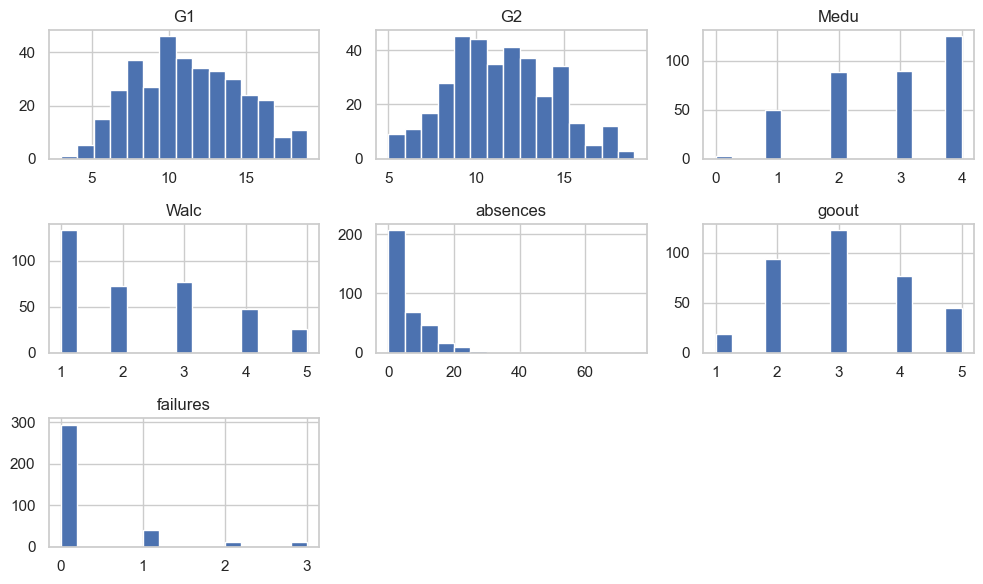

In [64]:
sns.set(style="whitegrid")

variables_to_plot = ["G1", "G2", "Medu", "Walc", "absences", "goout", "failures"]

math_df_clean[variables_to_plot].hist(bins=15, figsize=(10, 6))
plt.tight_layout()
plt.show()

From these histograms, we can see that:
* G1 and G2 are roughly bell-shaped around 10-12 without extreme outliers
* Medu is an ordinal variable on a small (0-4) scale (with more students having mothers who have higher education)
* Walc is an ordinal variable on a small (1-5) scale (with most students in middle category - consuming alchocol during weekend between 2 and 4)
* absences is the most skewed - as commented earlier in the project (EDA part), most students have few to no absences, but a small number of students have very high numbers of absences
* goout is an ordinal variable on small (1-5) scale (with most students going out with friends often = 3)
* failures is also highly skewed - most students have 0 past failures and only few of them have 1-3 failures (small range!)

Since I will build a linear regression model, and linear regression is sensitive to extreme skewness and outliers (because it assumes normal distribution) I decided to:
* transform absences using log transform - this will compress very large values (70+ absences) and reduce the influence of such extreme outliers
* keep original scales of other features (for now) - since the skewness is moderate and/or range is quite small, their scale can be later normalized for modeling instead of transforming it completely

In [65]:
# keeping original cleaned dataset just in case we need it again
df = math_df_clean.copy()

df["absences_log"] = np.log(df["absences"] + 1)
print("Transformed absences:")
print(df["absences_log"])

features = ["G1", "G2", "Medu", "Walc", "absences_log", "goout", "failures"]
X = df[features]
y = df["G3"]

Transformed absences:
0      1.945910
1      1.609438
2      2.397895
3      1.098612
4      1.609438
         ...   
390    2.484907
391    1.386294
392    1.386294
393    0.000000
394    1.791759
Name: absences_log, Length: 357, dtype: float64


Log transformation with log(absences + 1) narrowed the range of the feature (and reduced the influence of extreme outliers on the regression line), while keeping 0 values as 0 (since log(1)=0).

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (285, 7)
X_test_scaled shape: (72, 7)


## Cross validation

In [67]:
# 5-fold CV seems like a good choice for this dataset size
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2",}

def evaluate_model_cv(model, X, y, cv, scoring):
    cv_results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1)
    
    # converting negative errors back to positive
    mae = -cv_results["test_MAE"].mean()
    mse = -cv_results["test_MSE"].mean()
    rmse = np.sqrt(mse)
    r2 = cv_results["test_R2"].mean()
    
    return mae, rmse, r2

Since in scikit-learn MAE and MSE are implemented as negative scores, I created a helper function to convert negative errors back to positive - it's more logical to me to search for a smaller number that equals better results because, after all, we want to minimize the error (this is just a step for me to help me in interpretation).

---
# 5. Model training

## Training several regression models

In [68]:
models = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),}

results = []

for name, model in models.items():
    mae, rmse, r2 = evaluate_model_cv(model, X_train_scaled, y_train, cv=kf, scoring=scoring)
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results)
print(results_df)

              model       MAE      RMSE        R2
0  LinearRegression  0.653296  0.848403  0.930688
1      DecisionTree  0.835088  1.181732  0.866044
2      RandomForest  0.705643  0.909533  0.920822
3  GradientBoosting  0.719665  0.965456  0.910527


From these results, we can see that linear regression performed the best. It  has the lowest MAE and RMSE and the highest R2 among the four models. \
After linear regression, random forest and gradient boosting had similar performance, with random forest being slightly better than gradient boosting, but still not performing better then the linear model. Decision tree performed the worst, which makes sense because individual trees often overfit and generalize less well, especially with a small dataset.\
If we take into consideration features we have chosen, this result is expected - because G1 and G2 are by far the best predictors for G3 and have strong approximately linear relationship with it, tree models could not gain much more information from modelling more complex non-linear relationships. So with a feature set that is dominated by strongly linear predictors like G1 and G2, linear regression is hard to beat.\
If I were to choose a different set of features (by adding more features from the top 10 by feature importance and removing G1 and G2), the results could be completely different - tree-based models could maybe outperform linear regression.

## Training linear regression model

In [69]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_test_pred = lin_reg.predict(X_test_scaled)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

print("Linear Regression – Test set performance:")
print(f"MAE  : {test_mae:.3f}")
print(f"RMSE : {test_rmse:.3f}")
print(f"R2   : {test_r2:.3f}")
print()
print("Linear Regression - cross-validation performance:")
print(results_df.loc[0])

Linear Regression – Test set performance:
MAE  : 0.602
RMSE : 0.816
R2   : 0.931

Linear Regression - cross-validation performance:
model    LinearRegression
MAE              0.653296
RMSE             0.848403
R2               0.930688
Name: 0, dtype: object


We can see that scores for test set are very close to the cross-validated training scores.
* MAE is slightly better on test
* RMSE is also slighlty better on test
* R2 is roughly the same

We have managed to create a model that generalizes well (does not overfit) and that can explain about 93% of variability in final scores (G3) on unseen data.

## Residuals analysis

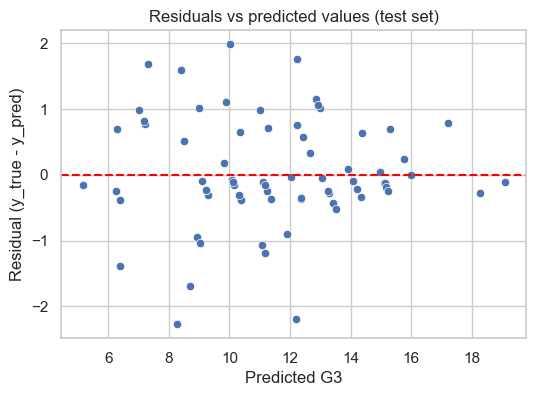

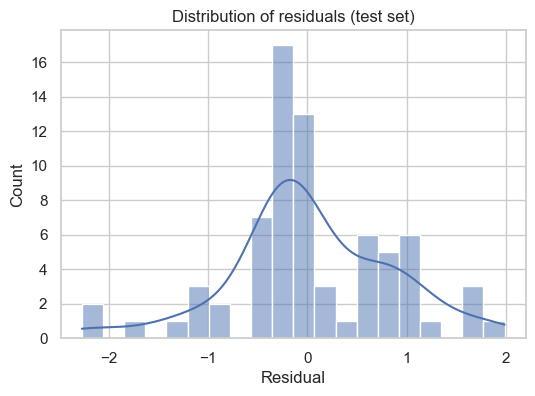

In [70]:
residuals = y_test - y_test_pred

# residuals vs predicted values
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_test_pred, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted G3")
plt.ylabel("Residual (y_true - y_pred)")
plt.title("Residuals vs predicted values (test set)")
plt.show()

# histogram of residuals
plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins=20, kde=True)
plt.xlabel("Residual")
plt.title("Distribution of residuals (test set)")
plt.show()

As can be seen from scatterplot, residuals are spread fairly evenly around zero across the range of predicted grades. There are no obvious non-linear patterns, so we can conclude that the variance of the error is reasonably constant. If we were to have more data, than maybe it would be easier to spot if there is some kind of a pattern here (it looks a bit like it might have a funnel shape >, but with this data there is no strong pattern of residuals increasing or decreasing with predicted G3).

In linear regression model, the errors should be normally distributed. In given histogram of residuals, we can see that most residuals are clustered around 0 and that the distribution is roughly symmetric in shape and that the KDE curve is fairly smooth and bell-like. This result is not perfect - there are a few more positive residuals (right tail is higher), but I do not consider this to be extreme enough. So we can conclude that the model does not systematically over or under predict final grade scores across most students.

Since I have chosen linear regression as my main model, there are effecitvely no meaningful hyperparameters to tune. I was contemplating on trying out Ridge regression, but, honestly, I am more interested in changing the feature set and seeing how that influences the process of choosing the best model. So, I will keep the same target (G3), but exclude G1 and G2 variables, to explore in more detail the influence of socio-economic and school-related features on final grade.  

---
# 6. Training with different feature set experiment

## Choosing a different feature set

Let's remind ourselves what were the strongest candidates for predicting G3.

In [71]:
print("Top 10 features by |correlation| with G3:")
print(top10_corr)
print()

print("Top 10 features by RF importance:")
print(top10_rf)
print()

print("Overlap (features in both top 10 lists):")
print(set_corr & set_rf)
print()
print("Only in correlation top 10:")
print(set_corr - set_rf)
print()
print("Only in RF-importance top 10:")
print(set_rf - set_corr)

Top 10 features by |correlation| with G3:
G2               0.965583
G1               0.891805
failures         0.293831
schoolsup_yes    0.238365
absences         0.213129
Medu             0.190308
Walc             0.190054
goout            0.177383
Fedu             0.158811
Fjob_teacher     0.158455
Name: G3, dtype: float64

Top 10 features by RF importance:
G2          0.931367
G1          0.010878
absences    0.005369
Walc        0.005087
goout       0.004387
famrel      0.003327
age         0.003189
health      0.002939
Medu        0.002447
freetime    0.002414
dtype: float64

Overlap (features in both top 10 lists):
{'G1', 'Medu', 'absences', 'G2', 'goout', 'Walc'}

Only in correlation top 10:
{'schoolsup_yes', 'failures', 'Fjob_teacher', 'Fedu'}

Only in RF-importance top 10:
{'famrel', 'health', 'freetime', 'age'}


In Model A I have chosen features: {G1, G2, Medu, Walc, absences_log, goout, failures}. In Model B I kept features {Medu, Walc, absences_log, goout, failures} and added {Fedu, age, health, famrel, freetime, schoolsup_yes}.

Insert from dataset documentation to better understand chosen features:
1. Fedu - father's education (numeric: 0 - none, 1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education) 
2. age - student's age (numeric: from 15 to 22)
3.	health - current health status (numeric: from 1 - very bad to 5 - very good)
4.	famrel - quality of family relationships (numeric: from 1 - very bad to 5 - excellent)
5.	freetime - free time after school (numeric: from 1 - very low to 5 - very high)
6.	schoolsup_yes - extra educational support (originally binary: yes or no)

So, I decided to add all features that were only in RF-importance top 10 list and all features but 1 (Fjob_teacher) that were only in correlation top 10 list, and exclude G1 and G2.

## Data preparation

In [72]:
# reminder: math_df_clean is not transformed, scaled and/or encoded!!

In [73]:
df = math_df_clean.copy()
df["absences_log"] = np.log(df["absences"] + 1)

X_full = df.drop(columns=["G3", "dbscan_label", "G3_zero_flag", "absences_outlier"])
y = df["G3"]

numeric_cols = X_full.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_full.select_dtypes(exclude=[np.number]).columns.tolist()

# reusing ColumnTransformer from feature selection method 2 (passthrough numeric, OneHotEncode categorical)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),])

X_full_trans = preprocessor.fit_transform(X_full)
feature_names = (
    numeric_cols
    + list(preprocessor.named_transformers_["cat"]
           .get_feature_names_out(categorical_cols)))

X_trans_df = pd.DataFrame(X_full_trans, columns=feature_names)
X_trans_df

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18.0,4.0,4.0,2.0,2.0,0.0,4.0,3.0,4.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,17.0,1.0,1.0,1.0,2.0,0.0,5.0,3.0,3.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,15.0,1.0,1.0,1.0,2.0,3.0,4.0,3.0,2.0,2.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0
3,15.0,4.0,2.0,1.0,3.0,0.0,3.0,2.0,2.0,1.0,...,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,16.0,3.0,3.0,1.0,2.0,0.0,4.0,3.0,2.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,20.0,2.0,2.0,1.0,2.0,2.0,5.0,5.0,4.0,4.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
353,17.0,3.0,1.0,2.0,1.0,0.0,2.0,4.0,5.0,3.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
354,21.0,1.0,1.0,1.0,1.0,3.0,5.0,5.0,3.0,3.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
355,18.0,3.0,2.0,3.0,1.0,0.0,4.0,4.0,1.0,3.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [74]:
features_B = ["Medu", "Fedu", "Walc", "absences_log", "goout", "failures", "age", "health", "famrel", "freetime", "schoolsup_yes"]
X_B = X_trans_df[features_B]

X_B_train, X_B_test, y_B_train, y_B_test = train_test_split(X_B, y, test_size=0.2, random_state=42)

scaler_B = StandardScaler()
scaler_B.fit(X_B_train)
X_B_train_scaled = scaler_B.transform(X_B_train)
X_B_test_scaled = scaler_B.transform(X_B_test)

results_B = []

for name, model in models.items():
    mae, rmse, r2 = evaluate_model_cv(
        model,
        X_B_train_scaled,
        y_B_train,
        cv=kf,
        scoring=scoring,
    )
    results_B.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

results_B_df = pd.DataFrame(results_B)

results_A_df = results_df.copy()
results_A_df["Model_type"] = "A (with G1, G2)"
results_B_df["Model_type"] = "B (no G1, G2)"
all_results =  pd.concat([results_A_df, results_B_df], ignore_index=True)
display(all_results)

,model,MAE,RMSE,R2,Model_type
0,LinearRegression,0.653296,0.848403,0.930688,"A (with G1, G2)"
1,DecisionTree,0.835088,1.181732,0.866044,"A (with G1, G2)"
2,RandomForest,0.705643,0.909533,0.920822,"A (with G1, G2)"
3,GradientBoosting,0.719665,0.965456,0.910527,"A (with G1, G2)"
4,LinearRegression,2.384492,2.985920,0.153257,"B (no G1, G2)"
5,DecisionTree,3.466667,4.408922,-0.861661,"B (no G1, G2)"
6,RandomForest,2.491596,3.131306,0.071319,"B (no G1, G2)"
7,GradientBoosting,2.658860,3.436740,-0.120353,"B (no G1, G2)"


From the results table we can see that Model B perform much much worse than Model A and this makes sense. Since Model B does not use G1 and G2 as features, and G1 and G2 carry most of the information for predicting G3, removing them and using socio-economic features by themselves is not sufficient to accurately predict individual final grades. If we look at linear regression R2 score, it drops from 0.93 to 0.15 - this shows us that socio-economic features explain only a small amount of variance in G3. So, it seems that predicting final grades relying on prior achievements is much more accurate that predicting it from other contextual factors. This does not mean that factors like family background, absences, failures and social life (alcohol consumption, going out) do not matter at all, but rather, taking just them into consideration will not predict final grade precisely. As our professor from Affective Computing often says, this is due to the beautiful variance of humans. :)

Although I have hoped for bit more interesting results from Model B models, I am disappointed to report that, when using only socio-economic and behavioural features, all four models perform substantially worse than in Model A. Again, linear regression achieves the best results (lowest MAE and RMSE and highest R2). Among tree-based models, it seems that random forest performed the best, while decision tree and gradient boosting performed so badly, that their R2 values are negative - they do not explain the variance in G3 any better than a simple mean predictor. 

## Training linear regression model B

In [75]:
lin_reg_B = LinearRegression()
lin_reg_B.fit(X_B_train_scaled, y_B_train)

y_B_test_pred = lin_reg_B.predict(X_B_test_scaled)

test_mae_B = mean_absolute_error(y_B_test, y_B_test_pred)
test_mse_B = mean_squared_error(y_B_test, y_B_test_pred)
test_rmse_B = np.sqrt(test_mse_B)
test_r2_B = r2_score(y_B_test, y_B_test_pred)

print("Model B – Linear Regression – Test set performance:")
print(f"MAE  : {test_mae_B:.3f}")
print(f"RMSE : {test_rmse_B:.3f}")
print(f"R2   : {test_r2_B:.3f}")
print()
print("Model B – Linear Regression – cross-validation performance:")
print(results_B_df.loc[0])

Model B – Linear Regression – Test set performance:
MAE  : 2.190
RMSE : 2.717
R2   : 0.234

Model B – Linear Regression – cross-validation performance:
model         LinearRegression
MAE                   2.384492
RMSE                   2.98592
R2                    0.153257
Model_type       B (no G1, G2)
Name: 0, dtype: object


When looking at test performance, it is slightly better than on cross-validation set, but the model is still weak (R2 = 0.23). It seems that in both cases (Model A and Model B linear regression) cross-validation proved to be a reliable estimate of generalization performance.

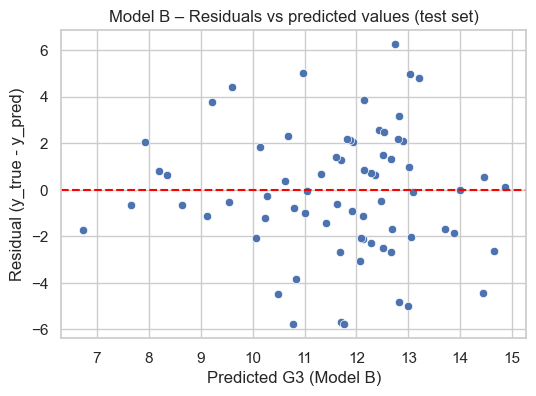

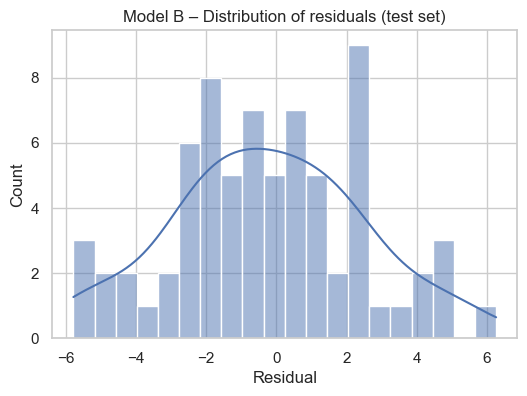

In [76]:
residuals_B = y_B_test - y_B_test_pred

# residuals vs predicted values
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_B_test_pred, y=residuals_B)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted G3 (Model B)")
plt.ylabel("Residual (y_true - y_pred)")
plt.title("Model B – Residuals vs predicted values (test set)")
plt.show()

# histogram of residuals
plt.figure(figsize=(6, 4))
sns.histplot(residuals_B, bins=20, kde=True)
plt.xlabel("Residual")
plt.title("Model B – Distribution of residuals (test set)")
plt.show()

In Model B, residuals are still centered roughly around zero and do not show a strong pattern with respect to the predicted values, so it seems that the linearity assumption is not that badly violated. However, we must take into consideration that the spread of residuals is much larger (from about −6 to +6), which is consistent with the higher MAE and RMSE. The histogram of residuals is wider and less peaked than in Model A (again bigger range/spread) - this indicates that prediction errors are generally larger when the model only uses socio‑economic and behavioural features.

---
# 7. Model evaluation & conclusion

In this project I built and compared several regression models to predict students’ final math grades. When earlier grades (G1, G2) were included as features (Model A), a simple linear regression model had the best and very strong performance:
* MAE = 0.65,
* RMSE = 0.85,
* R2 = 0.93.

In contrast, when only socio‑economic and behavioural variables were used (Model B), all models performed much worse. The best model was again linear regression, but with much worse performance:
* MAE = 2.19,
* RMSE = 2.71,
* R2 = 0.23 on the test set, and residuals were much more spread out.

This suggests that prior achievement/grades carries most of the predictive information for final grades, while background factors such as parental education, absences, failures and social life play a secondary role: they matter, but are not sufficient on their own to accurately predict individual outcomes.